# BEPAD: benchmark your associator

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/02_benchmark.ipynb)

Write a basic associator (DBSCAN), score it, see its mistakes, tune it, and prepare a leaderboard
submission. About 3 minutes. Documentation: [Benchmark your associator](https://bepad.readthedocs.io/en/latest/benchmark.html) ·
[Contribute](https://bepad.readthedocs.io/en/latest/contribute.html).

In [ ]:
%pip install -q "bepad>=0.1.3" scikit-learn
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"     # quieter downloads

## 1. An associator in a few lines

Subclass [`bepad.Associator`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.Associator) and fill in `associate(picks, stations)`: it gets one window's
picks and stations (never the labels) and returns **one integer per pick**: its earthquake, or −1
for noise. Settings passed to the class are in `self.config`.

The idea here: picks of one earthquake are close in **time and space**. DBSCAN groups picks in
(time, x / v, y / v), the station position turned into seconds with a speed `v`; isolated picks
stay −1 (noise).

In [ ]:
import numpy as np
from sklearn.cluster import DBSCAN
import bepad

class DBSCANAssociator(bepad.Associator):
    name = "dbscan-basic"

    def associate(self, picks, stations):
        st = stations.set_index("station").loc[picks.station]            # coordinates of each pick
        lat0 = st.latitude.mean()
        x = (st.longitude.to_numpy() - st.longitude.mean()) * 111.2 * np.cos(np.radians(lat0))   # km
        y = (st.latitude.to_numpy() - lat0) * 111.2
        v = self.config["velocity_kms"]
        X = np.c_[picks.t_rel_s.to_numpy(), x / v, y / v]               # seconds
        return DBSCAN(eps=self.config["eps_s"], min_samples=self.config["min_picks"]).fit_predict(X)

## 2. Run and score

[`run`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.Associator.run) does the loop, the timing and the scoring on a split; here 20
Texas test windows. The result has the predictions and a [`Report`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.metrics.Report).

In [ ]:
assoc = DBSCANAssociator(eps_s=3.0, min_picks=5, velocity_kms=6.0)
result = assoc.run("test", networks=["tx"], max_windows=20)

cols = ["event_precision", "event_recall", "event_f1", "pick_f1", "noise_rejection", "split_rate", "merge_rate"]
result.report.overall[cols].round(3)

,event_precision,event_recall,event_f1,pick_f1,noise_rejection,split_rate,merge_rate
0,0.247,0.624,0.354,0.405,0.738,0.195,0.08


| Metric | Question it answers |
|---|---|
| event precision / recall / F1 | did you find the earthquakes, without inventing extra ones? |
| pick F1 | did each pick go to the right earthquake? |
| noise rejection | did you leave the false picks unassociated? |
| split / merge rate | did you break an earthquake in two, or fuse two into one? |

Definitions: [Metrics](https://bepad.readthedocs.io/en/latest/reference/metrics.html). Scores per scenario:

In [ ]:
result.report.by_scenario[["scenario", "n_windows"] + cols].round(2)

,scenario,n_windows,event_precision,event_recall,event_f1,pick_f1,noise_rejection,split_rate,merge_rate
0,ev-high__noise-extreme,2.0,0.08,0.53,0.13,0.21,0.64,0.31,0.02
1,ev-high__noise-high,1.0,0.73,0.55,0.63,0.43,0.94,0.15,0.27
2,ev-high__noise-med,1.0,1.00,0.79,0.88,0.60,0.99,0.21,0.45
3,ev-low__noise-extreme,2.0,0.24,0.50,0.32,0.33,0.66,0.00,0.06
4,ev-low__noise-high,1.0,1.00,0.67,0.80,0.56,0.96,0.00,0.50
5,ev-low__noise-low,1.0,1.00,0.50,0.67,0.55,0.92,0.00,0.33
6,ev-low__noise-none,1.0,1.00,0.50,0.67,0.67,NaN,0.00,0.00
7,ev-med__noise-extreme,2.0,0.38,0.93,0.54,0.54,0.93,0.47,0.11
8,ev-med__noise-high,1.0,0.83,0.50,0.62,0.44,0.97,0.10,0.33
9,ev-med__noise-low,1.0,0.71,0.50,0.59,0.50,0.97,0.20,0.43


## 3. See the mistakes

[`plot_prediction`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.plots.plot_prediction): the true grouping (left) against yours
(right) for the window you did worst on; red circles are errors.

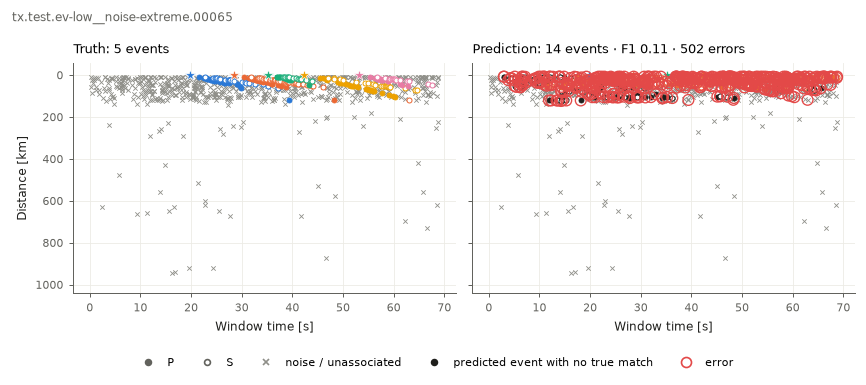

In [ ]:
from bepad.plots import plot_prediction

worst = result.report.per_window.sort_values("ari").window_id.iloc[0]     # lowest agreement with the truth
one = bepad.load("test", window_ids=[worst])
plot_prediction(one[0], result.predictions);

## 4. Tune on val, never on test

Try a few settings on the **validation** split, keep the best, and only then run the test split.

,eps_s,event_precision,event_recall,event_f1,pick_f1,noise_rejection,split_rate,merge_rate
0,1,0.786,0.196,0.314,0.043,0.999,0.062,0.321
1,2,0.506,0.750,0.604,0.365,0.962,0.518,0.139
2,3,0.526,0.732,0.612,0.549,0.858,0.223,0.103
3,4,0.438,0.696,0.538,0.539,0.689,0.116,0.096
4,6,0.537,0.652,0.589,0.491,0.441,0.071,0.147


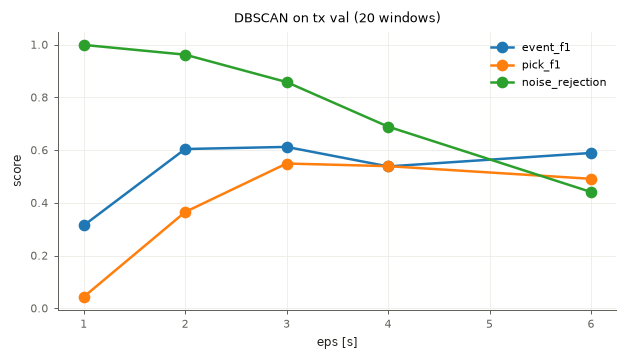

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

rows = []
for eps in [1, 2, 3, 4, 6]:
    r = DBSCANAssociator(eps_s=eps, min_picks=5, velocity_kms=6.0).run("val", networks=["tx"], max_windows=20, progress=False)
    rows.append({"eps_s": eps, **r.report.overall[cols].iloc[0].round(3).to_dict()})
tuning = pd.DataFrame(rows)

ax = tuning.plot(x="eps_s", y=["event_f1", "pick_f1", "noise_rejection"], marker="o", figsize=(6, 3))
ax.set(xlabel="eps [s]", ylabel="score", title="DBSCAN on tx val (20 windows)")
tuning

## 5. Prepare a submission

A leaderboard entry is a folder with your code (`associator.py`) and settings (`config.yaml`),
run on the test windows of the **BEPAD-10** networks, then sent with
[`bepad submit`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.leaderboard.submit) ([Contribute](https://bepad.readthedocs.io/en/latest/contribute.html)). Here, a
short version: 20 Texas windows, and `--dry-run`, which checks everything and sends nothing.

In [ ]:
import sys
!{sys.executable} -m bepad new dbscan-basic

created associators/dbscan-basic/ -- fill in associate() in associators/dbscan-basic/associator.py, then: bepad run associators/dbscan-basic --split val


In [ ]:
%%writefile associators/dbscan-basic/associator.py
import numpy as np
from sklearn.cluster import DBSCAN
import bepad

class Associator(bepad.Associator):
    name = "dbscan-basic"
    version = "0.1"
    authors = "BEPAD notebook"     # your name(s)
    method_type = "classical"
    training = "none"
    description = "DBSCAN on pick time and station position (position turned into seconds)."

    def associate(self, picks, stations):
        st = stations.set_index("station").loc[picks.station]
        lat0 = st.latitude.mean()
        x = (st.longitude.to_numpy() - st.longitude.mean()) * 111.2 * np.cos(np.radians(lat0))
        y = (st.latitude.to_numpy() - lat0) * 111.2
        v = self.config["velocity_kms"]
        X = np.c_[picks.t_rel_s.to_numpy(), x / v, y / v]
        return DBSCAN(eps=self.config["eps_s"], min_samples=self.config["min_picks"]).fit_predict(X)

Overwriting associators/dbscan-basic/associator.py


In [ ]:
%%writefile associators/dbscan-basic/config.yaml
eps_s: 3.0
min_picks: 5
velocity_kms: 6.0

Overwriting associators/dbscan-basic/config.yaml


In [ ]:
!{sys.executable} -m bepad run associators/dbscan-basic --split test --networks tx --max-windows 20 --out results/dbscan-basic
!{sys.executable} -m bepad submit results/dbscan-basic --code associators/dbscan-basic --dry-run

<bepad.Result dbscan-basic test 20 windows>
 event_precision  event_recall  event_f1  pick_precision  pick_recall  pick_f1  noise_rejection  split_rate  merge_rate  ari_mean
          0.2467        0.6242    0.3536          0.3853        0.426   0.4046            0.738      0.1946      0.0796    0.4108


[run] saved to results/dbscan-basic


Please fix these first:
  - the BEPAD-10 networks are required, missing: CM, JMA, NOA, R01, R05, R07, R09, ak, nc (run with --networks core, plus any other networks)


The dry run lists what is missing for a real entry (here: the BEPAD-10 networks). For the real
one, on your machine:

```bash
bepad run associators/dbscan-basic --split test --networks core --out results/dbscan-basic --workers 8
bepad submit results/dbscan-basic --code associators/dbscan-basic --dry-run   # check, see your row
bepad submit results/dbscan-basic --code associators/dbscan-basic             # send (pull request)
```